# 02 · Player profiles

The numbers every later analysis reads a player through. The back-test, role discovery and the
similarity search all start from these profiles, so each statistic in them has to describe the
player, not chance or the team around them.

1. **Which numbers describe a player?** The candidate statistics and their definitions, how
   reliable each one is within each comparison group, how much league and team drive it, and
   which ones repeat each other.

**Players:** outfield players of the scouting pool (Premier League, La Liga, Serie A and Ligue 1,
2015/16), compared within the comparison groups of `config/pipeline.yaml`. Carried over from
`01_data_exploration.ipynb`: minutes are real time on the pitch, rates are shrunk by measured
reliability, interceptions, pressures and clearances are compared within recording context, and
xG is StatsBomb's non-penalty xG as published.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups) and
Transfermarkt via [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)
(dates of birth). Only aggregated results are shown, as StatsBomb's licence requires. Tables are
built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from football_scouting.analysis.leagues import league_effect, team_effect
from football_scouting.analysis.metrics import (
    FAMILIES,
    LABELS,
    LOWER_IS_BETTER,
    OPEN_PLAY,
    PER_90,
    PROGRESSIVE_RULES,
    SUMMED,
    player_match_counts,
    progressive,
    rates,
)
from football_scouting.analysis.players import pool_player_seasons
from football_scouting.analysis.reliability import split_half_reliability, stabilisation_minutes
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
OUTFIELD = [g.code for g in cfg.comparison_groups if g.code != "GK"]
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
POOL = "match_id IN (SELECT match_id FROM matches WHERE scouting_pool)"

players = pool_player_seasons(con, cfg, age_on=cfg.backtest.market_view)
counts = player_match_counts(con)
season = rates(counts.groupby("player_id")[SUMMED].sum())
# The team a player spent most minutes with (103 players moved within the pool).
main_team = (
    counts.groupby(["player_id", "team_id"]).minutes.sum().reset_index()
    .sort_values(["minutes", "team_id"]).groupby("player_id").tail(1)
    .set_index("player_id").team_id
)  # fmt: skip
regulars = players[(players.minutes >= 900) & (players.comparison_group != "GK")]
regulars = regulars.set_index("player_id")
group = regulars.comparison_group.astype(str)
print(
    f"{len(players):,} pool players, {len(regulars):,} outfield players with 900+ minutes: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}" for g, n in group.value_counts()[OUTFIELD].items())
    + "."
)

2,176 pool players, 1,266 outfield players with 900+ minutes: centre-backs 261, full-backs 253, central midfielders 307, attacking midfielders and wingers 280, centre-forwards 165.


## 1. Which numbers describe a player?

The exploration measured 15 per-90 rates and a few ratios. A recruitment profile needs more:
how a player moves the ball forward, contests it in the air, presses after losing it, or loses
it. This section lists the candidates, settles the definitions left open (progressive passes and
carries) and tests every candidate three ways, within each comparison group:

- **reliability**: does a season tell players apart, or is it mostly noise?
- **league and team**: does the number describe the player, or where they play?
- **redundancy**: does it say something another number does not?

Reliability is measured on outfield players with 1,800+ minutes (two halves of 900); the other
tests on outfield players with 900+ minutes. Goalkeepers are left out here.

### 1.1 The candidates

46 statistics in seven families, all defined in `analysis.metrics`. Besides the 21 of the
exploration, the candidates are the location-based numbers of its section 6 and:

- **expected assists (xA)**: the xG of the shots a player's open-play passes set up;
- **through balls, switches of play and long passes** (30+ yards), and how often long passes
  and crosses are completed;
- **progressive passes and carries** under three rules, compared in 1.5;
- **aerial duels** and the share won;
- **times dribbled past** per 90, and **dribblers tackled**: tackles won over tackles won plus
  times dribbled past;
- **counterpressures** (pressures within five seconds of the team losing the ball) and
  **pressures in the final third**;
- **ball losses per touch**: miscontrols and dispossessions;
- **fouls won**.

Two of them rest on how StatsBomb records a contest between two players. An aerial duel is
"won" on the winner's action (a pass, clearance, shot or miscontrol flagged `aerial_won`) and
"lost" as a duel event of the loser; a completed dribble leaves a "dribbled past" event for the
defender beaten. Both are checked below.

In [2]:
catalogue = pd.DataFrame(
    {
        "statistics": {f: len(ms) for f, ms in FAMILIES.items()},
        "per 90": {f: sum(m in PER_90 for m in ms) for f, ms in FAMILIES.items()},
        "ratios": {f: sum(m not in PER_90 for m in ms) for f, ms in FAMILIES.items()},
        "members": {f: "; ".join(LABELS[m] for m in ms) for f, ms in FAMILIES.items()},
    }
)
catalogue.loc["All"] = [*catalogue.iloc[:, :3].sum(), ""]
with pd.option_context("display.max_colwidth", None):
    display(catalogue)

aerials = counts.groupby("match_id")[["aerials_won", "aerials_lost"]].sum()
dribbles_beaten = con.sql(f"""
    WITH done AS (
        SELECT match_id, competition_id, match_seconds, team_id FROM dribbles
        WHERE {POOL} AND outcome = 'Complete'),
    past AS (
        SELECT competition_id, count(*) AS dribbled_past FROM dribbled_past
        WHERE {POOL} GROUP BY ALL)
    SELECT competition_id, count(*) AS completed,
           avg(EXISTS (SELECT 1 FROM dribbled_past p
                       WHERE p.match_id = done.match_id AND p.team_id <> done.team_id
                         AND abs(p.match_seconds - done.match_seconds) <= 2)::INT) AS beaten,
           any_value(past.dribbled_past) / count(*) AS per_dribble
    FROM done JOIN past USING (competition_id) GROUP BY competition_id
""").df()
print(
    f"Aerial duels: won = lost in {(aerials.aerials_won == aerials.aerials_lost).sum():,} of "
    f"{len(aerials):,} matches ({aerials.aerials_won.sum():,} each)."
)
done = dribbles_beaten.completed
print(
    "Completed dribbles with a 'dribbled past' event of the other team within 2 seconds: "
    f"{(dribbles_beaten.beaten * done).sum() / done.sum():.1%} of {done.sum():,}; "
    "'dribbled past' events per completed dribble: "
    f"{dribbles_beaten.per_dribble.min():.2f} to {dribbles_beaten.per_dribble.max():.2f} by league."
)

,statistics,per 90,ratios,members
Shooting,7,5,2,Non-penalty shots; Non-penalty xG; Non-penalty goals; Non-penalty xG per shot; Finishing: non-penalty goals minus xG per shot; Touches in the opposition box; Passes received in the box
Chance creation,6,5,1,"Key passes (open play); Expected assists (xA, open play); Completed passes into the box; Through balls; Open-play crosses; Cross completion"
Passing and progression,9,7,2,Open-play passes; Open-play pass completion; Long passes (30+ yards); Long pass completion; Switches of play; Completed passes into the final third; Progressive passes (10 yards); Progressive passes (zones); Progressive passes (25% closer)
Carrying and ball security,9,7,2,Dribbles attempted; Dribble success; Carries into the final third; Carries into the box; Progressive carries (10 yards); Progressive carries (zones); Progressive carries (25% closer); Fouls won; Ball losses per touch
Defending,10,9,1,Pressures; Counterpressures; Pressures in the final third; Tackles; Dribblers tackled; Times dribbled past; Interceptions; Ball recoveries; Clearances; Blocks
Aerial duels,2,1,1,Aerial duels; Aerial duels won
Position,3,0,3,"Average touch position (x, towards goal); Average touch distance from the centre line; Height of defensive actions (x)"
All,46,34,12,


Aerial duels: won = lost in 1,517 of 1,517 matches (64,925 each).
Completed dribbles with a 'dribbled past' event of the other team within 2 seconds: 100.0% of 29,079; 'dribbled past' events per completed dribble: 1.09 to 1.11 by league.


### 1.2 Reliability within each comparison group

The exploration measured reliability over all outfield players, rates centred within group and
league (section 2 of `01_data_exploration.ipynb`). A profile compares players within one group,
so here reliability is also measured within each group: the same 50 random split halves, rates
centred within league. The number is the correlation between two halves of 900 minutes, which
is the share of the spread between players at 900 minutes that is real. A statistic enters a
profile at 0.4 or more; shrinkage then pulls the noisy part towards the group average.

In [3]:
METRICS = [m for ms in FAMILIES.values() for m in ms]
GRID = [180, 270, 360, 450, 600, 750, 900]

long_season = players[(players.minutes >= 1800) & (players.comparison_group != "GK")]
long_group = long_season.comparison_group.astype(str)
curve = split_half_reliability(
    counts[counts.player_id.isin(long_season.player_id)],
    (long_group + " | " + long_season.league).set_axis(long_season.player_id),
    METRICS,
    GRID,
)
K = stabilisation_minutes(curve, METRICS)
r900 = {"All outfield": curve[curve.target == 900][METRICS].mean()}
used = {"All outfield": curve[curve.target == 900].players.mean()}
for g in OUTFIELD:
    sub = long_season[long_group == g]
    by_group = split_half_reliability(
        counts[counts.player_id.isin(sub.player_id)],
        sub.league.set_axis(sub.player_id),
        METRICS,
        [900],
    )
    r900[g], used[g] = by_group[METRICS].mean(), by_group.players.mean()
r900 = pd.DataFrame(r900)
print(
    "Players with 900 minutes in both halves (mean of 50 draws): "
    + ", ".join(f"{GROUP_NAMES.get(g, g).lower()} {n:.0f}" for g, n in used.items())
    + "."
)

Players with 900 minutes in both halves (mean of 50 draws): all outfield 702, centre-backs 172, full-backs 137, central midfielders 186, attacking midfielders and wingers 127, centre-forwards 79.


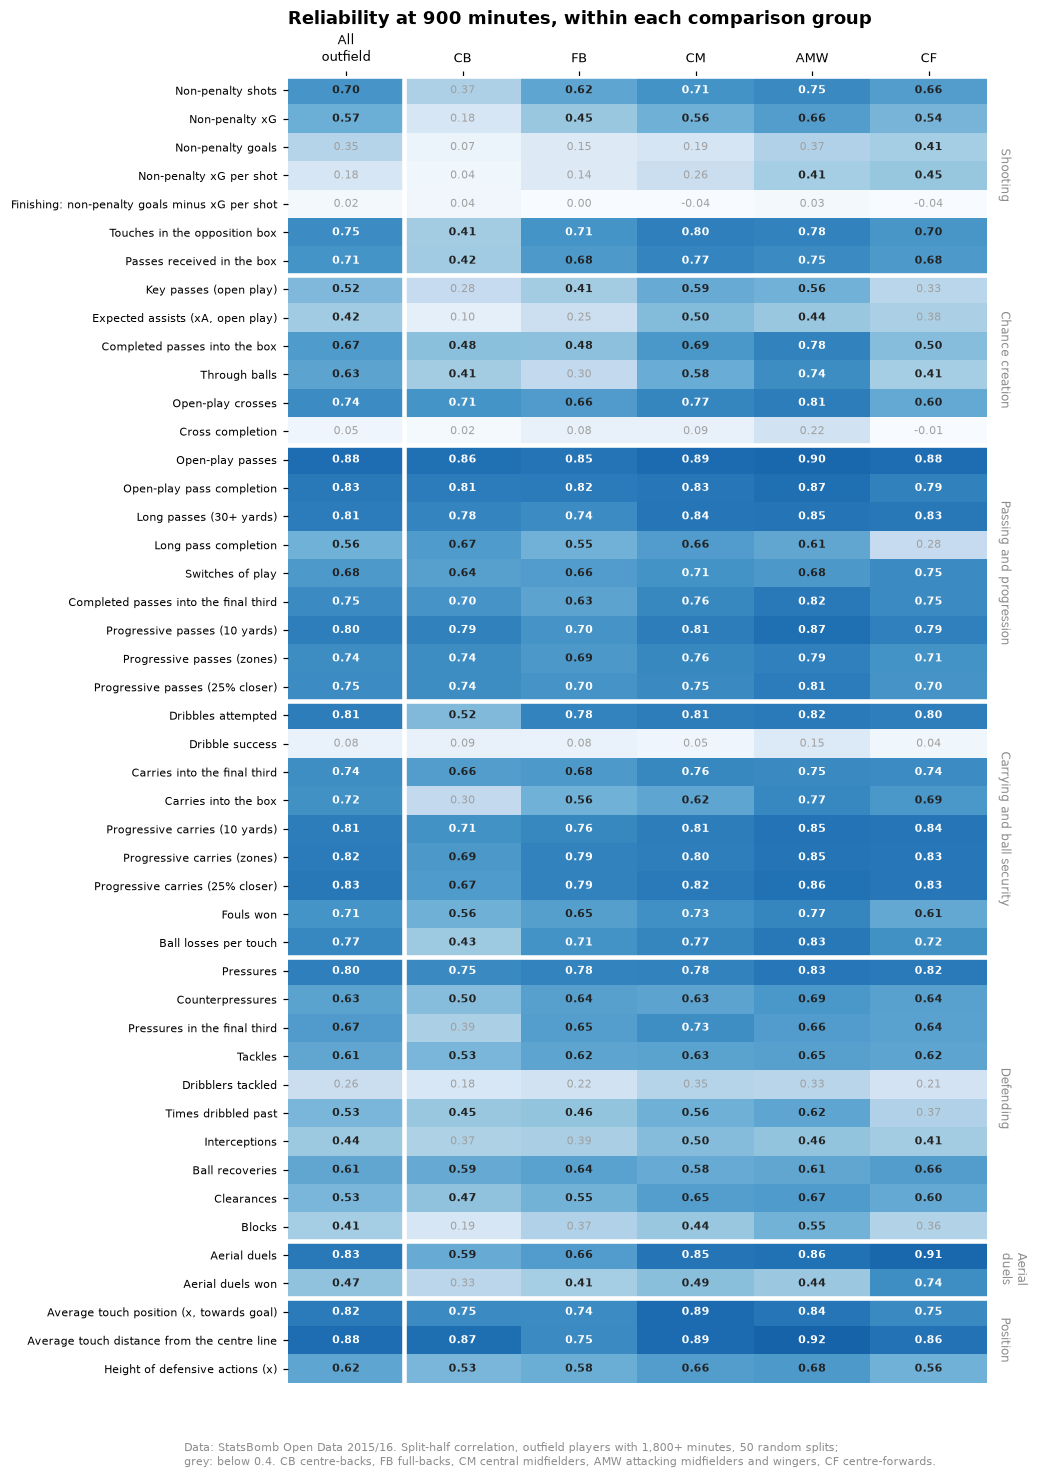

In [4]:
COLUMNS = ["All outfield", *OUTFIELD]
fig, ax = plt.subplots(figsize=(8.2, 13.2))
shown = r900.loc[METRICS, COLUMNS]
ax.imshow(shown.clip(lower=0), cmap="Blues", vmin=0, vmax=1.15, aspect="auto")
for (i, j), v in np.ndenumerate(shown.to_numpy()):
    ax.text(
        j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
        color="white" if v >= 0.7 else ("#222222" if v >= 0.4 else "#A0A0A0"),
        fontweight="bold" if v >= 0.4 else "normal",
    )  # fmt: skip
ax.set_xticks(range(len(COLUMNS)), ["All\noutfield", *OUTFIELD], fontsize=8.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(METRICS)), [LABELS[m] for m in METRICS], fontsize=7.5)
start = 0
for family, members in FAMILIES.items():
    ax.axhline(start - 0.5, color="white", lw=3)
    ax.text(
        len(COLUMNS) - 0.4, start + len(members) / 2 - 0.5,
        family if len(members) > 3 else family.replace(" ", "\n"), rotation=-90,
        ha="left", va="center", fontsize=8, color=GREY,
    )  # fmt: skip
    start += len(members)
ax.axvline(0.5, color="white", lw=3)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Reliability at 900 minutes, within each comparison group", pad=34)
fig.subplots_adjust(top=0.92, bottom=0.02)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Split-half correlation, outfield players with 1,800+ "
    "minutes, 50 random splits;\ngrey: below 0.4. CB centre-backs, FB full-backs, CM central "
    "midfielders, AMW attacking midfielders and wingers, CF centre-forwards.",
)
plt.show()

In [5]:
# Minutes at which a rate is half signal, half noise: K = 900 (1 - r) / r within each group.
k_by_group = (900 * (1 - r900[OUTFIELD]) / r900[OUTFIELD]).where(r900[OUTFIELD] > 0)
EXAMPLES = [
    "passes", "xg", "key_passes", "xa", "interceptions", "aerial_win_rate",
    "long_pass_completion", "carries_into_box",
]  # fmt: skip
k_table = pd.concat([K.rename("All outfield (curve fit)"), k_by_group], axis=1).loc[EXAMPLES]
k_table.index = [LABELS[m] for m in EXAMPLES]
reliable = r900[OUTFIELD].ge(0.4)
print(
    "Statistics at 0.4 or more: "
    + ", ".join(f"{g} {n}" for g, n in reliable.sum().items())
    + f" of {len(METRICS)}; below 0.4 in every group: "
    + ", ".join(LABELS[m] for m in r900.index[~reliable.any(axis=1)])
    + "."
)
k_table.round(-1).astype("Int64")

Statistics at 0.4 or more: CB 31, FB 36, CM 40, AMW 41, CF 37 of 46; below 0.4 in every group: Finishing: non-penalty goals minus xG per shot, Cross completion, Dribble success, Dribblers tackled.


,All outfield (curve fit),CB,FB,CM,AMW,CF
Open-play passes,130,140,160,110,100,120
Non-penalty xG,720,4000,1110,690,470,760
Key passes (open play),890,2260,1290,630,720,1820
"Expected assists (xA, open play)",1350,8140,2700,890,1140,1450
Interceptions,1240,1540,1410,890,1060,1300
Aerial duels won,1080,1850,1320,940,1160,320
Long pass completion,790,440,720,460,570,2260
Carries into the box,360,2100,710,560,270,410


### 1.3 League and team

The exploration found attacking and passing numbers on one scale across the four leagues
(league partial η² of 0.03 or less), and three defensive numbers recorded differently between
leagues or, in the Premier League, from 28 December 2015 (match week 19). The same tests for the
candidates, on players with 900+ minutes: the league's partial η² within comparison group, each
league's gap from the group average, and the change from match week 19 in team-match totals (the
second part of the season over the first), in the Premier League and at most in another league.
Shown: the statistics above 0.03, or whose rate per 90 changes by more than 10%.

In [6]:
d = season.loc[regulars.index].assign(
    league=regulars.league, group=group, team=main_team.reindex(regulars.index)
)
league_table = pd.DataFrame({m: league_effect(d, m) for m in METRICS}).T

weeks = con.sql("SELECT match_id, match_week >= 19 AS late FROM matches").df()
team_matches = (
    counts.groupby(["match_id", "competition_id", "team_id"])[SUMMED].sum().reset_index()
    .merge(weeks, on="match_id")
)  # fmt: skip
halves = team_matches.groupby(["competition_id", "late"])[SUMMED].sum()
half_rates = rates(halves)
shift = half_rates.xs(True, level="late") / half_rates.xs(False, level="late")
PL_ID = next(c.competition_id for c in cfg.statsbomb.competitions if c.name == "Premier League")
league_table["Premier League from week 19"] = shift.loc[PL_ID] - 1
league_table["largest elsewhere"] = (
    (shift.drop(index=PL_ID) - 1).abs().max().reindex(league_table.index)
)
# Changes are read on per-90 rates (finishing, for one, sits around zero).
changed = league_table.index.isin(list(PER_90)) & (
    league_table["Premier League from week 19"].abs() > 0.10
)
flagged = league_table[(league_table["partial η²"] > 0.03) | changed]
flagged = flagged.sort_values("partial η²", ascending=False)
flagged.index = [LABELS[m] for m in flagged.index]
FORMATS = {
    "partial η²": "{:.3f}", **dict.fromkeys(LEAGUES, "{:+.0f}%"),
    "Premier League from week 19": "{:+.0%}", "largest elsewhere": "±{:.0%}",
}  # fmt: skip
flagged.apply(lambda col: col.map(FORMATS[col.name].format))

,partial η²,La Liga,Ligue 1,Premier League,Serie A,Premier League from week 19,largest elsewhere
Interceptions,0.245,+37%,-10%,-7%,-20%,+189%,±8%
Pressures,0.080,-6%,+7%,-8%,+7%,+18%,±7%
Clearances,0.080,-7%,-3%,+19%,-7%,+16%,±2%
Pressures in the final third,0.080,-8%,+7%,-12%,+12%,+21%,±7%
Fouls won,0.063,+6%,-1%,-18%,+13%,-2%,±6%
Times dribbled past,0.061,+13%,-8%,+9%,-13%,-4%,±4%
"Average touch position (x, towards goal)",0.046,-1%,-2%,+1%,+2%,+1%,±1%
Dribblers tackled,0.044,-4%,+6%,-4%,+1%,-0%,±2%
Counterpressures,0.042,-3%,+7%,-9%,+4%,+14%,±6%


In [7]:
LEAGUE_OF = {c.competition_id: c.name for c in cfg.statsbomb.competitions}
by_league = counts.groupby("competition_id")
per_match = (
    by_league[["fouls_won", "dribbles_completed", "dribbled_past"]].sum()
    .div(by_league.match_id.nunique(), axis=0) / 2
)  # fmt: skip
per_match.index = per_match.index.map(LEAGUE_OF)
per_match.columns = ["Fouls won", "Completed dribbles", "Times dribbled past"]
per_match.rename_axis("Per team and match").round(1)

,Fouls won,Completed dribbles,Times dribbled past
Per team and match,,,
Premier League,12.0,10.6,11.5
Ligue 1,14.0,8.8,9.8
La Liga,15.2,10.6,11.6
Serie A,15.9,8.4,9.2


**Fouls won** and **times dribbled past** are new to the list, and neither is a recording
artefact. Fouls won follow the refereeing: Serie A matches have a third more fouls than Premier
League matches, so the same player draws more fouls in Italy. Times dribbled past follow the
opposition: every completed dribble leaves a "dribbled past" event, and Premier League and La
Liga teams complete more dribbles per match. In both, the league gap is about the league, not
the player. **Counterpressures** and **pressures in the final third** are pressures, and change
with them in the Premier League from match week 19; they fall under the rule already set for
pressures (compared within recording context).

The team matters more than the league. With one to three players per team and group, teams
"explain" about 7% of any number by chance alone, so the share below is adjusted for it, as R²
is for the number of predictors. The team includes its league.

In [8]:
team_table = pd.Series({m: team_effect(d, m) for m in METRICS}, name="team share")
top = team_table.sort_values(ascending=False).head(12)
print(
    f"Median over the {len(METRICS)} statistics: {team_table.median():.2f}; "
    f"below 0.05: {(team_table < 0.05).sum()}."
)
top.rename(index=LABELS).round(2).to_frame()

Median over the 46 statistics: 0.08; below 0.05: 11.


,team share
Open-play passes,0.48
Open-play pass completion,0.38
Interceptions,0.26
Long pass completion,0.23
Progressive passes (10 yards),0.21
Height of defensive actions (x),0.21
Touches in the opposition box,0.19
"Average touch position (x, towards goal)",0.18
Clearances,0.18
Through balls,0.18


Passing volume and pass completion depend most on the team: a player passes as often, and as
safely, as the team keeps the ball. Interceptions follow, through the league's recording. How
much of this is possession, and whether it should be adjusted for, is the subject of section 2.

### 1.4 Redundancy

Two statistics that rank a group's players the same way take two slots in a profile to say one
thing. For each group, Spearman correlations between the statistics reliable in that group
(0.4 or more), on players with 900+ minutes. Below: every pair at 0.8 or more in at least one
group, with the correlation in each group where both are reliable. Goals, finishing and dribble
success are left out: the exploration found them mostly noise and they do not rank players.

In [9]:
NOT_RANKED = ["goals", "finishing", "dribble_success"]
pairs = {}
for g in OUTFIELD:
    ok = [m for m in METRICS if r900.loc[m, g] >= 0.4 and m not in NOT_RANKED]
    rho = d.loc[group == g, ok].corr("spearman")
    for i, a in enumerate(ok):
        for b in ok[i + 1 :]:
            pairs.setdefault((a, b), {})[g] = rho.loc[a, b]
pairs = pd.DataFrame(pairs).T.reindex(columns=OUTFIELD)
close = pairs[pairs.abs().ge(0.8).any(axis=1)]
close = close.loc[close.abs().max(axis=1).sort_values(ascending=False).index]
close.index = [f"{LABELS[a]} ~ {LABELS[b]}" for a, b in close.index]
print(f"{len(close)} pairs at 0.8 or more in at least one group.")
close.map(lambda v: "" if pd.isna(v) else f"{v:.2f}")

22 pairs at 0.8 or more in at least one group.


,CB,FB,CM,AMW,CF
Progressive carries (zones) ~ Progressive carries (25% closer),0.95,0.98,0.98,0.98,0.97
Progressive passes (zones) ~ Progressive passes (25% closer),0.98,0.96,0.97,0.95,0.91
Touches in the opposition box ~ Passes received in the box,0.95,0.94,0.96,0.89,0.87
Progressive carries (10 yards) ~ Progressive carries (zones),0.92,0.94,0.96,0.94,0.96
Progressive carries (10 yards) ~ Progressive carries (25% closer),0.89,0.92,0.94,0.92,0.95
Completed passes into the final third ~ Progressive passes (10 yards),0.81,0.89,0.93,0.93,0.85
Carries into the final third ~ Progressive carries (10 yards),0.77,0.93,0.89,0.87,0.89
Carries into the final third ~ Progressive carries (zones),0.75,0.93,0.88,0.86,0.89
Carries into the final third ~ Progressive carries (25% closer),0.71,0.89,0.87,0.83,0.85
Open-play passes ~ Progressive passes (10 yards),0.84,0.77,0.85,0.87,0.71


Three kinds of overlap. The rules for progressive passes, and for progressive carries, rank
players much the same way (1.5 picks one). Passes into the final third repeat progressive
passes, carries into the final third repeat progressive carries, and passes received in the box
repeat touches in the box, in almost every group. The rest meet in one or two groups, mostly
among central midfielders: pass completion and long pass completion, key passes and xA, long
passes and switches, shots, xG and touches in the box, pressures and counterpressures.

### 1.5 Progressive passes and carries

A progressive pass or carry moves the ball substantially towards the opponent's goal. The
definition varies by provider; three common rules were tested on completed open-play passes and
on carries:

- **10 yards**: at least 10 yards towards the goal line, passes starting beyond the defending
  40% of the pitch and carries ending in the other half (FBref's rule, without its reference to
  the previous six passes);
- **zones**: at least 30 m closer to the centre of the goal within the own half, 15 m from the
  own half into the other, 10 m within the other half (Wyscout's rule, on a 105 m pitch);
- **25% closer**: ending at least 25% closer to the centre of the goal.

The rules differ in where they count. The figure shows, by where the ball starts, the share of
passes and carries each rule counts.

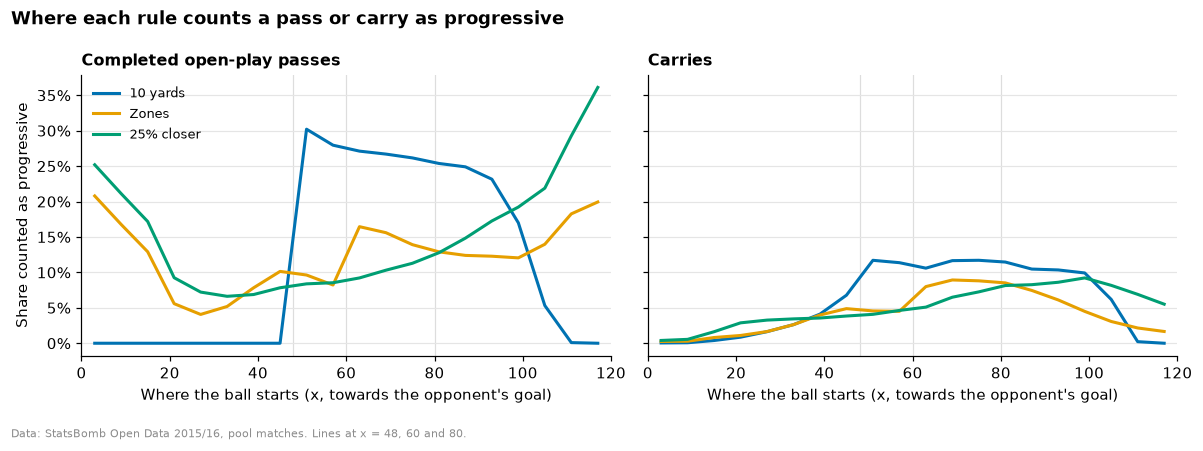

In [10]:
BINS = 6  # units along the pitch
where_counted = {}
for kind, table, extra in [("pass", "passes", f"AND {OPEN_PLAY} AND completed"),
                           ("carry", "carries", "")]:  # fmt: skip
    rules = ", ".join(f'avg({progressive(r, kind)}::INT) AS "{r}"' for r in PROGRESSIVE_RULES)
    where_counted[kind] = con.sql(f"""
        SELECT least(floor(x / {BINS}) * {BINS} + {BINS} / 2, 117) AS x, count(*) AS n, {rules}
        FROM {table} WHERE {POOL} {extra} GROUP BY 1 ORDER BY 1
    """).df()

RULE_NAMES = {"10y": "10 yards", "zones": "Zones", "25pct": "25% closer"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (kind, title) in zip(
    axes, [("pass", "Completed open-play passes"), ("carry", "Carries")], strict=True
):
    w = where_counted[kind]
    for colour, rule in zip(OKABE_ITO, PROGRESSIVE_RULES, strict=False):
        ax.plot(w.x, w[rule], color=colour, lw=2, label=RULE_NAMES[rule])
    for edge in (48, 60, 80):
        ax.axvline(edge, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_xlim(0, 120)
    ax.set_xlabel("Where the ball starts (x, towards the opponent's goal)")
    ax.set_title(title, fontsize=10.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share counted as progressive")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle(
    "Where each rule counts a pass or carry as progressive", x=0.01, ha="left",
    fontweight="bold", fontsize=12,
)  # fmt: skip
credit(fig, "Data: StatsBomb Open Data 2015/16, pool matches. Lines at x = 48, 60 and 80.")
fig.tight_layout()
plt.show()

In [11]:
def summary(prefix: str, volume: str) -> pd.DataFrame:
    rows = {}
    for rule in PROGRESSIVE_RULES:
        m = f"{prefix}_{rule}"
        within = {g: d.loc[group == g, [m, volume, f"{prefix}_zones"]].corr("spearman")
                  for g in OUTFIELD}  # fmt: skip
        rows[RULE_NAMES[rule]] = {
            "per 90, median player": d[m].median(),
            "reliability, lowest group": r900.loc[m, OUTFIELD].min(),
            "reliability, highest group": r900.loc[m, OUTFIELD].max(),
            "team share": team_table[m],
            f"Spearman with {LABELS[volume].lower()}": np.median(
                [c.loc[m, volume] for c in within.values()]
            ),
            "Spearman with zones": np.median(
                [c.loc[m, f"{prefix}_zones"] for c in within.values()]
            ),
        }
    return pd.DataFrame(rows).T


print("Progressive passes (Spearman: median over the five groups)")
display(summary("progressive_passes", "passes").round(2))
print("Progressive carries")
display(summary("progressive_carries", "dribbles").round(2))

Progressive passes (Spearman: median over the five groups)


,"per 90, median player","reliability, lowest group","reliability, highest group",team share,Spearman with open-play passes,Spearman with zones
10 yards,4.76,0.70,0.87,0.21,0.84,0.79
Zones,3.14,0.69,0.79,0.08,0.60,1.00
25% closer,3.04,0.70,0.81,0.09,0.62,0.96


Progressive carries


,"per 90, median player","reliability, lowest group","reliability, highest group",team share,Spearman with dribbles attempted,Spearman with zones
10 yards,2.38,0.71,0.85,0.08,0.7,0.94
Zones,1.40,0.69,0.85,0.07,0.7,1.00
25% closer,1.39,0.67,0.86,0.08,0.7,0.98


The 10-yard rule ignores the defending 40% of the pitch and, beyond it, counts a quarter to a
third of all passes, since most forward passes in midfield cover 10 yards; near the goal, 10
yards forward is no longer possible. So it mostly counts passes: it is the most reliable, but it
ranks players by passing volume (Spearman 0.84 with open-play passes) and depends most on the
team (0.21). Zones and 25% closer count long passes from deep, ask more in midfield, and keep
counting near the goal. The two rank players almost the same way (0.91 to 0.98), keep most of
the reliability, and depend far less on the team (0.08 and 0.09) and on passing volume (0.60 and
0.62). For carries the three rules agree closely in every group.

**Zones** is the rule kept, for passes and carries: it measures progress rather than volume, it
is a standard in the industry (Wyscout), and it treats passes and carries alike. 25% closer
would do as well.

### 1.6 The profiles

Each comparison group's profile takes up to 12 statistics:

- reliable within the group (0.4 or more at 900 minutes);
- not goals, finishing or dribble success (mostly noise; exploration, sections 2 and 5);
- no two at a Spearman correlation of 0.8 or more within the group: of a pair, the more
  reliable or the one a scout reads more directly stays;
- covering the families each group's role calls for. For attackers, xG per 90 comes with shot
  volume and shot quality (as set in the exploration, section 5); position descriptors (touch position, width,
  height of defensive actions) describe a role, not how well it is played, and are kept for role
  discovery;
- fouls won and times dribbled past stay out: the first measures the league's refereeing as much
  as the player, the second the opposition's dribbling, and dribblers tackled, its fair version,
  is noise in every group.

The lists are kept in `config/pipeline.yaml` (`profiles`).

In [12]:
# Kept in config/pipeline.yaml (`profiles`), which every later notebook reads.
PROFILES = {g: list(statistics) for g, statistics in cfg.profiles.items()}


def profile_check(g: str) -> dict:
    ms = PROFILES[g]
    rho = d.loc[group == g, ms].corr("spearman").abs().to_numpy()
    np.fill_diagonal(rho, np.nan)
    return {
        "statistics": len(ms),
        "lowest reliability": r900.loc[ms, g].min(),
        "highest Spearman between two": np.nanmax(rho),
        "families": len({f for f, members in FAMILIES.items() for m in ms if m in members}),
    }


pd.DataFrame({GROUP_NAMES[g]: profile_check(g) for g in OUTFIELD}).T.round(2)

,statistics,lowest reliability,highest Spearman between two,families
Centre-backs,12.0,0.43,0.73,4.0
Full-backs,12.0,0.41,0.76,5.0
Central midfielders,12.0,0.50,0.69,5.0
Attacking midfielders and wingers,12.0,0.41,0.72,5.0
Centre-forwards,12.0,0.45,0.65,6.0


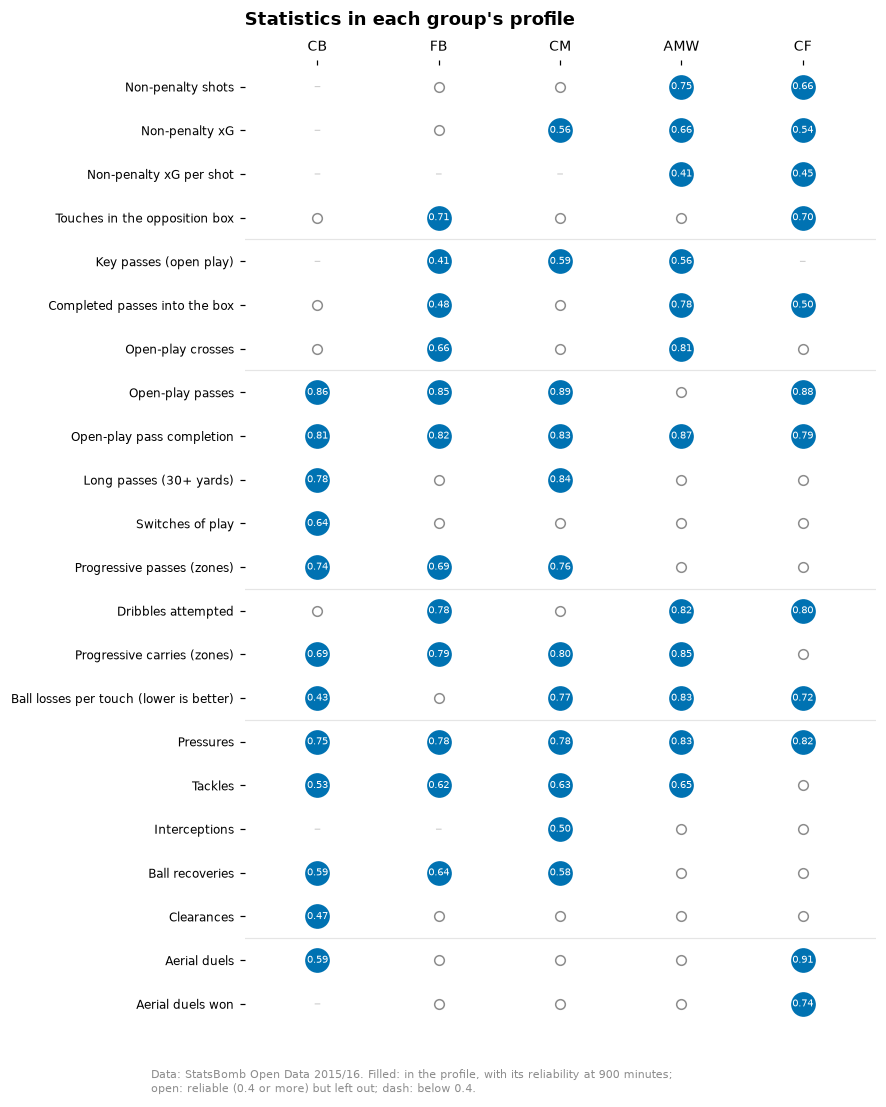

In [13]:
in_any = [m for m in METRICS if any(m in ms for ms in PROFILES.values())]
fig, ax = plt.subplots(figsize=(7.4, 9.6))
for j, g in enumerate(OUTFIELD):
    for i, m in enumerate(in_any):
        r = r900.loc[m, g]
        if m in PROFILES[g]:
            ax.scatter(j, i, s=230, color=OKABE_ITO[0], zorder=3)
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6.5, color="white",
                    zorder=4)  # fmt: skip
        elif r >= 0.4:
            ax.scatter(j, i, s=40, facecolor="white", edgecolor=GREY, lw=1, zorder=3)
        else:
            ax.text(j, i, "–", ha="center", va="center", fontsize=9, color="#C8C8C8")
labels = [LABELS[m] + (" (lower is better)" if m in LOWER_IS_BETTER else "") for m in in_any]
ax.set_yticks(range(len(in_any)), labels, fontsize=8)
ax.set_xticks(range(len(OUTFIELD)), OUTFIELD, fontsize=9)
ax.xaxis.tick_top()
ax.set_ylim(len(in_any) - 0.5, -0.5)
ax.set_xlim(-0.6, len(OUTFIELD) - 0.4)
start = 0
for members in FAMILIES.values():
    n = sum(m in in_any for m in members)
    if n and start:
        ax.axhline(start - 0.5, color="#E5E5E5", lw=0.8)
    start += n
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Statistics in each group's profile", pad=26)
fig.subplots_adjust(top=0.93, bottom=0.02)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Filled: in the profile, with its reliability at 900 "
    "minutes;\nopen: reliable (0.4 or more) but left out; dash: below 0.4.",
)
plt.show()

### What section 1 shows

- **Candidates.** 46 statistics in seven families. StatsBomb's records of contests hold up:
  aerial duels won equal aerial duels lost in every match, and every completed dribble leaves a
  "dribbled past" event for the defender.
- **Reliability depends on the group.** The same statistic can be signal in one group and noise
  in another: xG per 90 is 0.66 among attacking midfielders and wingers but 0.18 among
  centre-backs; the share of aerial duels won is 0.74 among centre-forwards but 0.33 among
  centre-backs, whose shares sit close together (half of them between 61% and 70%). Interceptions and blocks fall below 0.4 for
  centre-backs. Cross completion, dribble success, dribblers tackled and finishing are noise in
  every group. Each group's rates are therefore shrunk with the group's own K.
- **League and team.** Fouls won (refereeing) and times dribbled past (opposition) carry league
  gaps that are not about the player. Counterpressures and pressures in the final third change
  with the Premier League's recording, like pressures. The team weighs more than the league on
  passing volume and pass completion, the starting point of section 2.
- **Progressive actions** follow Wyscout's zones: a measure of progress rather than passing
  volume, depending less than half as much on the team as the 10-yard rule.
- **Profiles.** 12 statistics per group, each reliable in its group, no pair correlated at 0.8
  or more, covering what the role does.